# 02 — Dual Hierarchy Construction: CIFAR-100 Semantic Tree vs. Ward Confusion Tree

**Feature**: `F2` (`02-dual-hierarchy-trees` | `EPIC-02`)  
**Architecture**: `AD-002` (Semantic vs. Ward Confusion Hierarchy Ablation), `AD-004` (Scenario 1 & 2 Splits), `AD-008` (Thin Notebook Orchestration on Remote JupyterHub)

This notebook builds, inspects, visualizes, and serializes both hierarchy modes into `FastHierarchyTree` `.npz` archives:
1. **Mode A — Native Semantic Hierarchy** (`src.trees.semantic_tree.build_semantic_tree`): Virtual Root $\rightarrow$ 20 Coarse Superclasses $\rightarrow$ 99 Negative Leaves (Scenario 1) or 100 Fine Leaves (Scenario 2).
2. **Mode B — Data-Driven Ward Confusion Hierarchy** (`src.trees.confusion_tree.build_confusion_tree`): Estimates a validation confusion matrix $C \in \mathbb{R}^{100 \times 100}$, computes symmetric normalized distances $D_{i,j} = 1 - \frac{C^{\text{off}}_{i,j} + C^{\text{off}}_{j,i}}{2 \cdot \max(C^{\text{off}})}$, and converts the Ward linkage dendrogram into a binary `FastHierarchyTree` (`2K - 1` nodes).
3. **Visual Diagnostics & Serialization**: Renders confusion distance heatmaps, plots the Ward linkage dendrogram, and saves `.npz` tree artifacts for `F3` / `F4`.

In [1]:
from pathlib import Path
import os
import sys

REPO_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
from scipy.cluster.hierarchy import dendrogram
import seaborn as sns

from src.utils.seed import set_global_seed
from src.utils.experiment_config import (
    ExecutionMode,
    ExperimentConfig,
    get_isolated_paths,
    print_execution_banner,
    save_provenance_metadata,
    validate_provenance_metadata,
)
from src.data.cifar100_taxonomy import get_cifar100_taxonomy
from src.data.extract_embeddings import extract_or_generate_embeddings, load_embedding_cache
from src.data.splits import (
    DEFAULT_SCENARIO1_TARGETS,
    IMBALANCE_RATIOS,
    build_scenario1_split,
    build_scenario2_split,
)
from src.trees.base_tree import FastHierarchyTree
from src.trees.semantic_tree import build_semantic_tree
from src.trees.confusion_tree import (
    build_confusion_tree,
    compute_confusion_distance_matrix,
    estimate_validation_confusion_matrix,
)

# Execution mode: REAL by default for scientific runs; SMOKE for testing
EXECUTION_MODE = ExecutionMode.REAL
if os.environ.get("EXECUTION_MODE"):
    EXECUTION_MODE = ExecutionMode(os.environ["EXECUTION_MODE"].lower())
elif "pytest" in sys.modules:
    EXECUTION_MODE = ExecutionMode.SMOKE

config = ExperimentConfig(execution_mode=EXECUTION_MODE)
print_execution_banner(config, notebook_name="02_tree_construction")
paths = get_isolated_paths(config, repo_root=REPO_ROOT)

SEED = set_global_seed(42)
taxonomy = get_cifar100_taxonomy()
print(f"Repository root: {REPO_ROOT} | Seed: {SEED}")


EXPERIMENT MODE: REAL
Dataset: CIFAR-100
Synthetic fallback: DISABLED
Scientific results: ENABLED
Notebook: 02_tree_construction
Mode: REAL
Output directory: /home/mlima/workspace/mcts-hnm/results/real
Repository root: /home/mlima/workspace/mcts-hnm | Seed: 42


## 1. Load Cached Tier-1 Embeddings & Construct Scenario 1 / Scenario 2 Index Pools

Loads `embeddings/cifar100_resnet18.pt` produced by `notebooks/01_data_and_embeddings.ipynb` (or synthesizes a deterministic fallback fixture when running standalone smoke checks before downloading CIFAR-100).

In [2]:
CACHE_PATH = paths.embeddings_dir / "cifar100_resnet18.pt"
META_PATH = paths.embeddings_dir / "cifar100_resnet18.pt.meta.json"

if config.execution_mode == ExecutionMode.REAL:
    if not CACHE_PATH.exists():
        raise FileNotFoundError(
            f"Real CIFAR-100 embeddings not found at {CACHE_PATH}. "
            "Please execute notebooks/01_data_and_embeddings.ipynb in REAL mode first."
        )
    if META_PATH.exists():
        validate_provenance_metadata(META_PATH, expected_mode=ExecutionMode.REAL)
    bundle = load_embedding_cache(CACHE_PATH)
    train_emb = bundle["train"]["embeddings"]
    train_labels = bundle["train"]["fine_labels"].numpy()
    val_emb = bundle["val"]["embeddings"]
    val_labels = bundle["val"]["fine_labels"].numpy()
    print(f"Loaded real cached ResNet-18 embeddings from {CACHE_PATH}")
else:
    if not CACHE_PATH.exists():
        bundle = extract_or_generate_embeddings(config=config, cache_path=CACHE_PATH)
    else:
        bundle = load_embedding_cache(CACHE_PATH)
    train_emb = bundle["train"]["embeddings"]
    train_labels = bundle["train"]["fine_labels"].numpy()
    val_emb = bundle["val"]["embeddings"]
    val_labels = bundle["val"]["fine_labels"].numpy()
    print(f"Loaded SMOKE synthetic embeddings from {CACHE_PATH}")

scenario2_split = build_scenario2_split(train_labels)
scenario1_split = build_scenario1_split(
    fine_labels=train_labels,
    target_class=DEFAULT_SCENARIO1_TARGETS[0],
    pos_fraction=IMBALANCE_RATIOS["1:50"],
    seed=SEED,
)
print(f"Scenario 2 classes: {len(scenario2_split.class_to_indices)} | Scenario 1 negative classes: {len(scenario1_split.negative_class_to_indices)}")


Loaded real cached ResNet-18 embeddings from /home/mlima/workspace/mcts-hnm/embeddings/real/cifar100_resnet18.pt
Scenario 2 classes: 100 | Scenario 1 negative classes: 99


## 2. Build Mode A — Native CIFAR-100 Semantic Hierarchy (`build_semantic_tree`)

In [3]:
sem_tree_s2 = build_semantic_tree(scenario2_split.class_to_indices, taxonomy=taxonomy)
sem_tree_s1 = build_semantic_tree(scenario1_split.negative_class_to_indices, taxonomy=taxonomy)

print(
    f"[Semantic S2] nodes={sem_tree_s2.num_nodes}, leaves={sem_tree_s2.num_leaves}, "
    f"root_instances={sem_tree_s2.instance_counts[0]}"
)
print(
    f"[Semantic S1 ({scenario1_split.target_class_name})] nodes={sem_tree_s1.num_nodes}, "
    f"leaves={sem_tree_s1.num_leaves}, root_instances={sem_tree_s1.instance_counts[0]}"
)

[Semantic S2] nodes=121, leaves=100, root_instances=45000
[Semantic S1 (beaver)] nodes=120, leaves=99, root_instances=44550


## 3. Build Mode B — Data-Driven Ward Confusion Hierarchy (`build_confusion_tree`)

In [4]:
confusion_mat_100 = estimate_validation_confusion_matrix(
    train_embeddings=train_emb,
    train_labels=train_labels,
    val_embeddings=val_emb,
    val_labels=val_labels,
    num_classes=100,
    seed=SEED,
)
dist_mat_100 = compute_confusion_distance_matrix(confusion_mat_100)

conf_tree_s2, linkage_s2, _ = build_confusion_tree(
    confusion_mat_100,
    scenario2_split.class_to_indices,
    return_linkage=True,
    taxonomy=taxonomy,
)
conf_tree_s1, linkage_s1, _ = build_confusion_tree(
    confusion_mat_100,
    scenario1_split.negative_class_to_indices,
    return_linkage=True,
    taxonomy=taxonomy,
)

print(
    f"[Ward Confusion S2] nodes={conf_tree_s2.num_nodes}, leaves={conf_tree_s2.num_leaves}, "
    f"max_depth={int(conf_tree_s2.depths.max())}, root_instances={conf_tree_s2.instance_counts[0]}"
)
print(
    f"[Ward Confusion S1] nodes={conf_tree_s1.num_nodes}, leaves={conf_tree_s1.num_leaves}, "
    f"max_depth={int(conf_tree_s1.depths.max())}, root_instances={conf_tree_s1.instance_counts[0]}"
)

[Ward Confusion S2] nodes=199, leaves=100, max_depth=20, root_instances=45000
[Ward Confusion S1] nodes=197, leaves=99, max_depth=20, root_instances=44550


## 4. Visualize Confusion Distance Heatmap & Ward Dendrogram + Export `.npz` Artifacts

Saved & verified tree artifacts:
  - /home/mlima/workspace/mcts-hnm/embeddings/real/trees/semantic_tree_scenario2.npz
  - /home/mlima/workspace/mcts-hnm/embeddings/real/trees/confusion_tree_scenario2.npz (nodes=199)


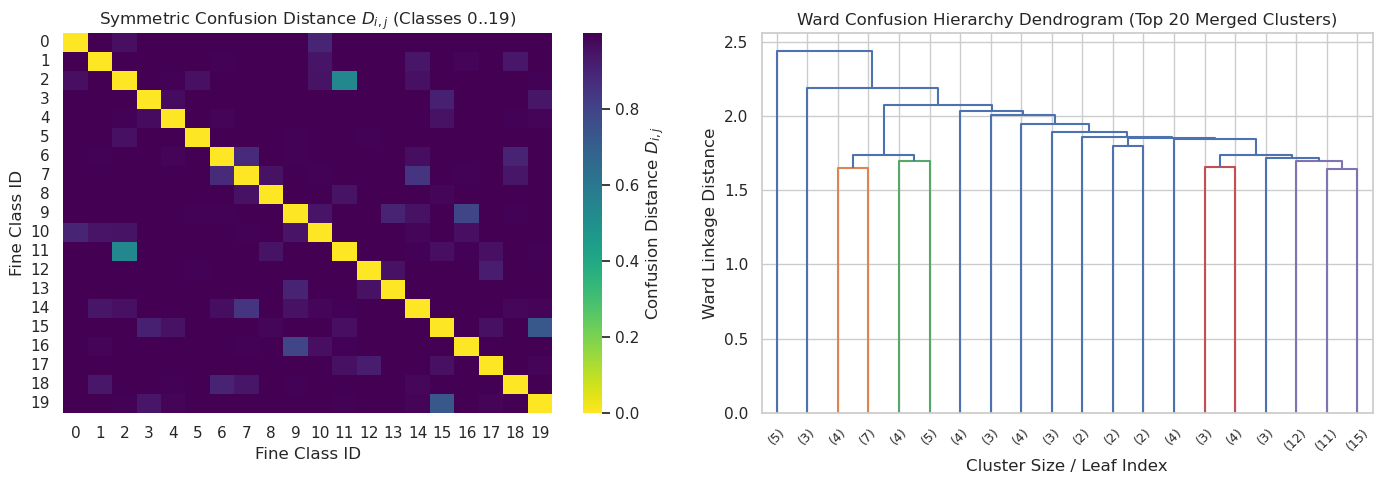

In [5]:
TREE_ARTIFACT_DIR = paths.embeddings_dir / "trees"
TREE_ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
sem_s2_path = sem_tree_s2.save(TREE_ARTIFACT_DIR / "semantic_tree_scenario2.npz")
conf_s2_path = conf_tree_s2.save(TREE_ARTIFACT_DIR / "confusion_tree_scenario2.npz")
save_provenance_metadata(sem_s2_path, config, extra={"tree_type": "semantic", "scenario": 2})
save_provenance_metadata(conf_s2_path, config, extra={"tree_type": "confusion", "scenario": 2, "linkage": "ward"})

# Also save to legacy path REPO_ROOT / "embeddings" / "trees" for backward compatibility with earlier suite
legacy_dir = REPO_ROOT / "embeddings" / "trees"
legacy_dir.mkdir(parents=True, exist_ok=True)
sem_tree_s2.save(legacy_dir / "semantic_tree_scenario2.npz")
conf_tree_s2.save(legacy_dir / "confusion_tree_scenario2.npz")

reloaded_conf = FastHierarchyTree.load(conf_s2_path)
print(f"Saved & verified tree artifacts:\n  - {sem_s2_path}\n  - {conf_s2_path} (nodes={reloaded_conf.num_nodes})")

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Confusion distance submatrix for first 20 fine classes
sns.heatmap(
    dist_mat_100[:20, :20],
    cmap="viridis_r",
    ax=axes[0],
    cbar_kws={"label": "Confusion Distance $D_{i,j}$"},
)
axes[0].set_title("Symmetric Confusion Distance $D_{i,j}$ (Classes 0..19)")
axes[0].set_xlabel("Fine Class ID")
axes[0].set_ylabel("Fine Class ID")

# Right: Top levels of the 100-class Ward Confusion Dendrogram
dendrogram(
    linkage_s2,
    truncate_mode="lastp",
    p=20,
    ax=axes[1],
    leaf_rotation=45.0,
    leaf_font_size=9.0,
)
axes[1].set_title("Ward Confusion Hierarchy Dendrogram (Top 20 Merged Clusters)")
axes[1].set_xlabel("Cluster Size / Leaf Index")
axes[1].set_ylabel("Ward Linkage Distance")

plt.tight_layout()
plt.show()
